# Лабораторная работа №7: Автоматическая разметка изображений с помощью VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Определить schema аннотации.
- Получить структурированные ответы VLM с retry.
- Проверить выборку человеком и обучить downstream baseline.


## Теоретическая часть

Авторазметка — это data pipeline: schema → generation → parsing → validation → confidence proxy → human audit. Нельзя терять сырой ответ модели: он нужен для трассировки ошибок и повторной обработки.


### Математическая постановка

Agreement для поля можно оценивать Cohen $\kappa=(p_o-p_e)/(1-p_e)$. Для редких классов важнее class-wise precision/recall, чем общая accuracy.


### Материалы

- [JSON Schema](https://json-schema.org/learn/getting-started-step-by-step)
- [Pydantic](https://docs.pydantic.dev/latest/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Полный эксперимент (`FAST_DEV_RUN=False`) требует GPU и ручной экспертизы captions. Классы CIFAR-10 служат проверяемым эталоном, а не ответами VLM. Установите torchvision, transformers, accelerate, bitsandbytes, pydantic, scikit-learn. В Colab сохраните `artifacts/` на Drive до начала инференса. FAST_DEV_RUN проверяет загрузку данных и схему без фиктивных метрик.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Источник и классы

*Вес: 1 балл.*

**Постановка.** Этап «источник и классы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Загрузите раздельные части CIFAR-10 и зафиксируйте перечень классов.
2. Сохраните и предъявите train/test CIFAR-10 и список классов.

**Результат.** train/test CIFAR-10 и список классов.

**Критерий принятия.** Задание считается принятым, если train/test CIFAR-10 и список классов получены из фактических входов этого этапа и доступны для проверки.

In [2]:
# Загружаем CIFAR-10 и фиксируем классы как проверяемый эталон.
from torchvision.datasets import CIFAR10
import pandas as pd

DATA_ROOT = Path("data")
DATA_ROOT.mkdir(exist_ok=True)

train_ds = CIFAR10(root=str(DATA_ROOT), train=True, download=True)
test_ds = CIFAR10(root=str(DATA_ROOT), train=False, download=True)

CIFAR_CLASSES = list(train_ds.classes)
assert CIFAR_CLASSES == list(test_ds.classes), "Классы train/test не совпали"

save_json("cifar_classes.json", CIFAR_CLASSES)
save_json("cifar_source.json", {
    "train_size": len(train_ds),
    "test_size": len(test_ds),
    "classes": CIFAR_CLASSES,
})

print(f"train={len(train_ds)}, test={len(test_ds)}, classes={len(CIFAR_CLASSES)}")
display(pd.DataFrame({"idx": range(len(CIFAR_CLASSES)), "class_name": CIFAR_CLASSES}))

train=50000, test=10000, classes=10


,idx,class_name
0,0,airplane
1,1,automobile
2,2,bird
3,3,cat
4,4,deer
5,5,dog
6,6,frog
7,7,horse
8,8,ship
9,9,truck


Источник и классы (cv07-09). Зафиксировать CIFAR-10 и 10 классов как эталон. Без него не с чем сравнивать VLM. Смысл: ground truth, а не «ответы модели».

### Стратифицированный отбор изображений

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отбор изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите равное число изображений каждого класса в train и test; запишите постоянные ID и пути.
2. Сохраните и предъявите пути и идентификаторы изображений по классам.

**Результат.** пути и идентификаторы изображений по классам.

**Критерий принятия.** Задание считается принятым, если пути и идентификаторы изображений по классам получены из фактических входов этого этапа и доступны для проверки.

In [3]:
# Отбираем равное число изображений на класс и материализуем их в artifacts/images.
from collections import defaultdict
import pandas as pd

TRAIN_PER_CLASS = 2 if FAST_DEV_RUN else 20
TEST_PER_CLASS = 2 if FAST_DEV_RUN else 10
rng = random.Random(SEED)

IMG_ROOT = ARTIFACTS / "images"
IMG_ROOT.mkdir(parents=True, exist_ok=True)

def select_split(ds, split, n_per_class):
    by_class = defaultdict(list)
    for idx, target in enumerate(ds.targets):
        by_class[int(target)].append(idx)

    rows = []
    for cls_idx, cls_name in enumerate(CIFAR_CLASSES):
        candidates = by_class[cls_idx][:]
        rng.shuffle(candidates)
        chosen = sorted(candidates[:n_per_class])

        for idx in chosen:
            img, _ = ds[idx]
            image_id = f"{split}-{cls_idx:02d}-{idx:05d}"
            out_path = IMG_ROOT / split / f"{cls_idx:02d}" / f"{image_id}.png"
            out_path.parent.mkdir(parents=True, exist_ok=True)
            img.save(out_path)

            # ARTIFACTS относительный, поэтому out_path уже относительный к cwd.
            # Сохраняем строкой как есть; cv07-13 проверяет Path(r["path"]).exists().
            rows.append({
                "image_id": image_id,
                "split": split,
                "class_idx": cls_idx,
                "class_name": cls_name,
                "label": cls_name,
                "source_index": int(idx),
                "path": str(out_path),
            })
    return rows

selection_records = (
    select_split(train_ds, "train", TRAIN_PER_CLASS)
    + select_split(test_ds, "test", TEST_PER_CLASS)
)

save_json("selection.json", selection_records)

df_sel = pd.DataFrame(selection_records)
display(df_sel.groupby(["split", "class_name"]).size().unstack(fill_value=0))
print(f"Всего отобрано: {len(selection_records)}")

class_name,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
split,,,,,,,,,,
test,10,10,10,10,10,10,10,10,10,10
train,20,20,20,20,20,20,20,20,20,20


Всего отобрано: 300


Стратифицированный отбор (cv07-11). Равное число примеров НА КЛАСС в train/test, постоянные ID. Смысл: воспроизводимость и отсутствие перекоса — иначе accuracy врёт из-за дисбаланса.

Стратифицированный отбор — просто «берём одинаковое количество картинок каждого класса», чтобы не было перекоса 

### Манифест изображений

*Вес: 1 балл.*

**Постановка.** Этап «манифест изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проверьте объём выборок и сохраните манифест с эталонными метками, не передавая их VLM.
2. Сохраните и предъявите artifacts/images.jsonl без пересечения train/test.

**Результат.** artifacts/images.jsonl без пересечения train/test.

**Критерий принятия.** Задание считается принятым, если artifacts/images.jsonl без пересечения train/test получены из фактических входов этого этапа и доступны для проверки.

In [4]:
# Сохраняем манифест с эталонными метками; VLM эти метки не получает.
import pandas as pd

if "selection_records" not in globals():
    selection_records = json.loads((ARTIFACTS / "selection.json").read_text(encoding="utf-8"))

train_ids = {r["image_id"] for r in selection_records if r["split"] == "train"}
test_ids = {r["image_id"] for r in selection_records if r["split"] == "test"}
assert train_ids.isdisjoint(test_ids), "Пересечение train/test по image_id"

for r in selection_records:
    assert Path(r["path"]).exists(), f"Нет файла: {r['path']}"

manifest_path = ARTIFACTS / "images.jsonl"
with manifest_path.open("w", encoding="utf-8") as f:
    for r in selection_records:
        row = {
            "image_id": r["image_id"],
            "split": r["split"],
            "path": r["path"],
            "class_name": r["class_name"],
            "label": r["label"],
            "source_index": r["source_index"],
        }
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

df_manifest = pd.DataFrame(selection_records)
display(df_manifest.groupby(["split", "class_name"]).size().unstack(fill_value=0))
print(f"Манифест сохранён: {manifest_path}, строк={len(selection_records)}")

class_name,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
split,,,,,,,,,,
test,10,10,10,10,10,10,10,10,10,10
train,20,20,20,20,20,20,20,20,20,20


Манифест сохранён: artifacts\images.jsonl, строк=300


Манифест (cv07-13). images.jsonl с путями, ID и метками, train/test не пересекаются. Смысл: единый источник правды для всех этапов; VLM метки не видит.

### Схема и парсер VLM-ответа

*Вес: 1 балл.*

**Постановка.** Этап «схема и парсер vlm-ответа» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Определите строгую схему class_name, caption, uncertain; отклоняйте незнакомые классы и пустые описания.
2. Сохраните и предъявите типизированная схема, prompt и функция parse.

**Результат.** типизированная схема, prompt и функция parse.

**Критерий принятия.** Задание считается принятым, если типизированная схема, prompt и функция parse получены из фактических входов этого этапа и доступны для проверки.

In [5]:
# Строгая схема + парсер JSON из ответа VLM.
import re
from pydantic import BaseModel, Field, field_validator, ConfigDict

if "CIFAR_CLASSES" not in globals():
    CIFAR_CLASSES = json.loads((ARTIFACTS / "cifar_classes.json").read_text(encoding="utf-8"))

class Annotation(BaseModel):
    model_config = ConfigDict(extra="forbid")

    class_name: str
    caption: str = Field(min_length=1)
    uncertain: bool = False

    @field_validator("class_name")
    @classmethod
    def class_must_be_known(cls, v: str) -> str:
        v = v.strip()
        if v not in CIFAR_CLASSES:
            raise ValueError(f"Незнакомый класс: {v}")
        return v

    @field_validator("caption")
    @classmethod
    def caption_must_be_nonempty(cls, v: str) -> str:
        v = v.strip()
        if not v:
            raise ValueError("Пустой caption")
        return v

VLM_PROMPT = (
    "You are an image annotation assistant. Look at the image and return ONLY valid JSON "
    "with exactly three keys: class_name, caption, uncertain. "
    f"class_name must be exactly one of: {CIFAR_CLASSES}. "
    "caption must be a short objective description in Russian, 5-15 words. "
    "uncertain must be a JSON boolean: true if the image is unclear or ambiguous, else false. "
    "Do not add markdown, explanations, or extra keys."
)

def parse_vlm_response(raw: str) -> Annotation:
    if not isinstance(raw, str) or not raw.strip():
        raise ValueError("Пустой ответ VLM")

    s = raw.strip()
    s = re.sub(r"^```(?:json)?\s*", "", s, flags=re.IGNORECASE)
    s = re.sub(r"\s*```$", "", s)

    start, end = s.find("{"), s.rfind("}")
    if start == -1 or end == -1 or end <= start:
        raise ValueError(f"JSON не найден: {raw[:200]!r}")

    obj = json.loads(s[start:end + 1])
    return Annotation(**obj)

save_json("annotation_schema.json", Annotation.model_json_schema())

example = '{"class_name": "cat", "caption": "рыжий кот сидит на траве", "uncertain": false}'
print("Пример разбора:", parse_vlm_response(example).model_dump())
print("Prompt:", VLM_PROMPT)

Пример разбора: {'class_name': 'cat', 'caption': 'рыжий кот сидит на траве', 'uncertain': False}
Prompt: You are an image annotation assistant. Look at the image and return ONLY valid JSON with exactly three keys: class_name, caption, uncertain. class_name must be exactly one of: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']. caption must be a short objective description in Russian, 5-15 words. uncertain must be a JSON boolean: true if the image is unclear or ambiguous, else false. Do not add markdown, explanations, or extra keys.


Schema и парсер (cv07-15). Строгая pydantic-схема class_name/caption/uncertain, отклонение незнакомых классов и пустых captions. Смысл: превратить свободный текст модели в валидируемые данные; иначе «bridge» протечёт в метрику как валидный ответ.

### Возобновляемое получение аннотаций

*Вес: 1 балл.*

**Постановка.** Этап «возобновляемое получение аннотаций» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вызовите Qwen2.5-VL для каждого изображения, повторяйте ошибочный JSON до трёх раз и сохраняйте исходные ответы по ID.
2. Сохраните и предъявите artifacts/annotations.jsonl с сырыми ответами и временем.

**Результат.** artifacts/annotations.jsonl с сырыми ответами и временем.

**Критерий принятия.** Задание считается принятым, если artifacts/annotations.jsonl с сырыми ответами и временем получены из фактических входов этого этапа и доступны для проверки.

In [6]:
# Реальный VLM-инференс с retry и немедленной записью сырых ответов.
import time
import pandas as pd

exec(VLM_LOADER, globals())  # определяет infer_image, model, processor

images = [
    json.loads(line)
    for line in (ARTIFACTS / "images.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]

ann_path = ARTIFACTS / "annotations.jsonl"
existing_rows = []
if ann_path.exists():
    existing_rows = [
        json.loads(line)
        for line in ann_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
ok_done = {r["image_id"] for r in existing_rows if r.get("status") == "ok"}

def append_jsonl(path: Path, row: dict):
    with path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print(f"К обработке: {len(images) - len(ok_done)} из {len(images)}")

for n, rec in enumerate(images, 1):
    image_id = rec["image_id"]
    if image_id in ok_done:
        continue

    last_error = None
    for attempt in range(1, 4):
        raw = None
        t0 = time.time()
        try:
            raw = infer_image(str(Path(rec["path"])), VLM_PROMPT)
            parsed = parse_vlm_response(raw).model_dump()
            row = {
                "image_id": image_id,
                "split": rec["split"],
                "path": rec["path"],
                "attempt": attempt,
                "status": "ok",
                "raw_response": raw,
                "parsed": parsed,
                "elapsed_sec": round(time.time() - t0, 4),
                "ts": time.time(),
            }
            append_jsonl(ann_path, row)
            ok_done.add(image_id)
            break
        except Exception as e:
            last_error = e
            row = {
                "image_id": image_id,
                "split": rec["split"],
                "path": rec["path"],
                "attempt": attempt,
                "status": "error",
                "raw_response": raw,
                "error": repr(e),
                "elapsed_sec": round(time.time() - t0, 4),
                "ts": time.time(),
            }
            append_jsonl(ann_path, row)
            time.sleep(0.3)

    if n % 10 == 0 or n == len(images):
        print(f"[{n}/{len(images)}] ok={len(ok_done)}, last_error={last_error!r}")

rows = [
    json.loads(line)
    for line in ann_path.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
df_ann = pd.DataFrame(rows)
if len(df_ann):
    latest = df_ann.sort_values("ts").groupby("image_id").tail(1)
    display(latest[["image_id", "split", "status", "attempt", "elapsed_sec"]].head(10))
print(f"Всего ok: {len(ok_done)} / {len(images)}")

W1022 11:12:50.058000 7332 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1022 11:12:55.473000 7332 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

К обработке: 300 из 300


c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[10/300] ok=10, last_error=None
[20/300] ok=20, last_error=None
[30/300] ok=30, last_error=None
[40/300] ok=40, last_error=None
[50/300] ok=50, last_error=None
[60/300] ok=60, last_error=None
[70/300] ok=70, last_error=None
[80/300] ok=80, last_error=None
[90/300] ok=90, last_error=None
[100/300] ok=100, last_error=None
[110/300] ok=110, last_error=None
[120/300] ok=120, last_error=None
[130/300] ok=130, last_error=None
[140/300] ok=140, last_error=None
[150/300] ok=150, last_error=None
[160/300] ok=160, last_error=None
[170/300] ok=169, last_error=None
[180/300] ok=179, last_error=None
[190/300] ok=189, last_error=None
[200/300] ok=199, last_error=None
[210/300] ok=209, last_error=None
[220/300] ok=219, last_error=None
[230/300] ok=229, last_error=None
[240/300] ok=239, last_error=None
[250/300] ok=249, last_error=None
[260/300] ok=259, last_error=None
[270/300] ok=269, last_error=None
[280/300] ok=279, last_error=None
[290/300] ok=286, last_error=1 validation error for Annotation
cla

,image_id,split,status,attempt,elapsed_sec
0,train-00-02967,train,ok,1,10.7122
1,train-00-03842,train,ok,1,9.8975
2,train-00-04337,train,ok,1,10.1409
3,train-00-07311,train,ok,1,9.8883
4,train-00-09533,train,ok,1,9.0142
5,train-00-11633,train,ok,1,9.7443
6,train-00-12325,train,ok,1,10.0273
7,train-00-13181,train,ok,1,10.0028
8,train-00-13660,train,ok,1,10.1140
9,train-00-15288,train,ok,1,10.5500


Всего ok: 296 / 300


### Проверка формата без GPU

*Вес: 1 балл.*

**Постановка.** Этап «проверка формата без gpu» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. В smoke-режиме проверьте только разбор валидного ответа, не вычисляя качество VLM.
2. Сохраните и предъявите проверка JSON-схемы в smoke-режиме.

**Результат.** проверка JSON-схемы в smoke-режиме.

**Критерий принятия.** Задание считается принятым, если проверка JSON-схемы в smoke-режиме получены из фактических входов этого этапа и доступны для проверки.

In [7]:
# Smoke-проверка схемы без VLM и без вычисления качества.
smoke_raw = '{"class_name": "cat", "caption": "рыжий кот сидит на траве", "uncertain": false}'
smoke_ann = parse_vlm_response(smoke_raw)

bad_raw = '{"class_name": "dragon", "caption": "мифическое существо", "uncertain": false}'
bad_rejected = False
try:
    parse_vlm_response(bad_raw)
except Exception as e:
    bad_rejected = True
    bad_error = repr(e)

smoke_result = {
    "valid_parsed": smoke_ann.model_dump(),
    "unknown_class_rejected": bad_rejected,
    "unknown_class_error": bad_error if bad_rejected else None,
}
save_json("smoke_schema_check.json", smoke_result)

print("Smoke parse:", smoke_ann.model_dump())
print("Unknown class rejected:", bad_rejected)

Smoke parse: {'class_name': 'cat', 'caption': 'рыжий кот сидит на траве', 'uncertain': False}
Unknown class rejected: True


По сути мы просто проверяем работоспособность кода парсера и обработчика ошибок  (доказательство того что именно модель выдала рандом а не ошибка в коде)

### Покрытие и матрица ошибок

*Вес: 1 балл.*

**Постановка.** Этап «покрытие и матрица ошибок» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Подсчитайте coverage, precision/recall и матрицу ошибок только по настоящим ответам модели на test.
2. Сохраните и предъявите artifacts/quality.json по ответам VLM.

**Результат.** artifacts/quality.json по ответам VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/quality.json по ответам VLM получены из фактических входов этого этапа и доступны для проверки.

,precision,recall,f1-score,support
airplane,0.909091,1.000000,0.952381,10.0
automobile,0.666667,1.000000,0.800000,10.0
bird,0.900000,0.900000,0.900000,10.0
cat,0.666667,0.800000,0.727273,10.0
deer,1.000000,0.600000,0.750000,10.0
dog,0.636364,0.700000,0.666667,10.0
frog,1.000000,0.800000,0.888889,10.0
horse,0.692308,0.900000,0.782609,10.0
ship,1.000000,0.285714,0.444444,7.0
truck,1.000000,0.900000,0.947368,10.0


coverage=0.970, accuracy=0.804, macro_f1=0.786


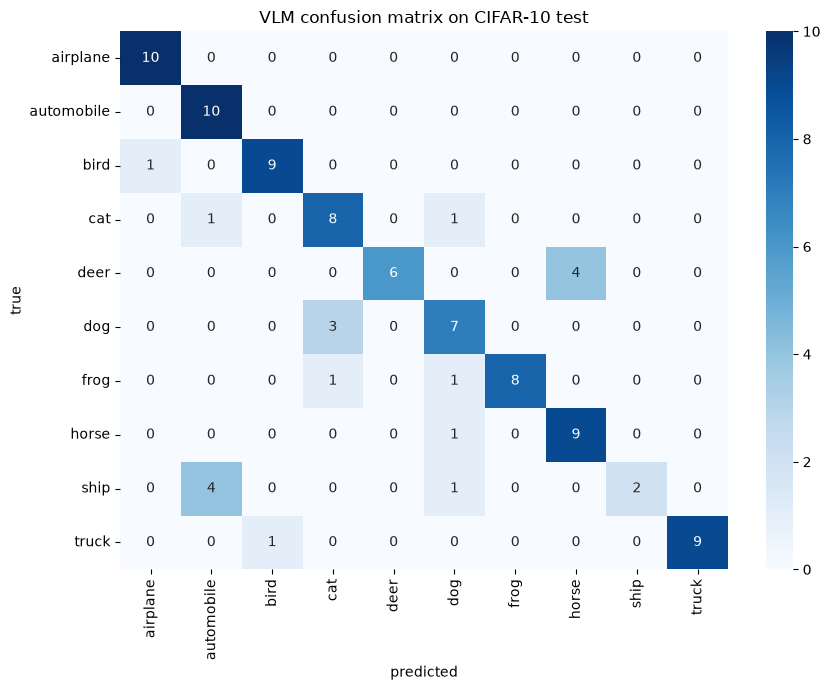

In [8]:
# Считаем качество только по реальным ok-ответам VLM на test.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

if "CIFAR_CLASSES" not in globals():
    CIFAR_CLASSES = json.loads((ARTIFACTS / "cifar_classes.json").read_text(encoding="utf-8"))

images = [
    json.loads(line)
    for line in (ARTIFACTS / "images.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
test_images = {r["image_id"]: r for r in images if r["split"] == "test"}

latest = {}
for line in (ARTIFACTS / "annotations.jsonl").read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    r = json.loads(line)
    if r.get("status") == "ok" and r.get("parsed"):
        latest[r["image_id"]] = r

valid = [(img, latest[image_id]) for image_id, img in test_images.items() if image_id in latest]
if not valid:
    raise RuntimeError("Нет ok-аннотаций VLM на test")

y_true = [img["class_name"] for img, _ in valid]
y_pred = [ann["parsed"]["class_name"] for _, ann in valid]
uncertain = [bool(ann["parsed"].get("uncertain", False)) for _, ann in valid]

labels_idx = list(range(len(CIFAR_CLASSES)))
y_true_idx = [CIFAR_CLASSES.index(x) for x in y_true]
y_pred_idx = [CIFAR_CLASSES.index(x) for x in y_pred]

cm = confusion_matrix(y_true_idx, y_pred_idx, labels=labels_idx)
report = classification_report(
    y_true_idx, y_pred_idx,
    labels=labels_idx,
    target_names=CIFAR_CLASSES,
    output_dict=True,
    zero_division=0,
)

coverage = len(valid) / len(test_images)
quality = {
    "n_test": len(test_images),
    "n_valid": len(valid),
    "coverage": coverage,
    "accuracy": report["accuracy"],
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "uncertain_rate": float(np.mean(uncertain)) if uncertain else 0.0,
    "labels": CIFAR_CLASSES,
    "per_class": {cls: report[cls] for cls in CIFAR_CLASSES},
    "confusion_matrix": cm.tolist(),
}
save_json("quality.json", quality)

display(pd.DataFrame(quality["per_class"]).T)
print(f"coverage={coverage:.3f}, accuracy={quality['accuracy']:.3f}, macro_f1={quality['macro_f1']:.3f}")

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CIFAR_CLASSES, yticklabels=CIFAR_CLASSES)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("VLM confusion matrix on CIFAR-10 test")
plt.tight_layout()
plt.savefig(ARTIFACTS / "confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

### Экспертная оценка описаний

*Вес: 1 балл.*

**Постановка.** Этап «экспертная оценка описаний» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Соберите отдельные экспертные оценки подписей и не подменяйте их пустым файлом.
2. Сохраните и предъявите artifacts/human_audit.jsonl с экспертными записями.

**Результат.** artifacts/human_audit.jsonl с экспертными записями.

**Критерий принятия.** Задание считается принятым, если artifacts/human_audit.jsonl с экспертными записями получены из фактических входов этого этапа и доступны для проверки.

Нужно оценить: 20 изображений

image_id: test-08-06747
VLM class: automobile | true class: ship
caption: Машина на воде


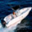


image_id: test-05-07474
VLM class: dog | true class: dog
caption: Белая собака с коричневыми ушами


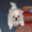


image_id: test-06-02613
VLM class: dog | true class: frog
caption: Собака с коричневым мехом и белой шерстью на голове.


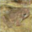


image_id: test-00-07815
VLM class: airplane | true class: airplane
caption: Большая белая самолетная модель на земле.


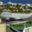


image_id: test-03-02269
VLM class: cat | true class: cat
caption: Кот сидит на дереве.


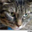


image_id: test-02-06699
VLM class: bird | true class: bird
caption: Птица сидит на ветке дерева.


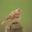


image_id: test-00-00491
VLM class: airplane | true class: airplane
caption: Самолет летит в небе.


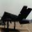


image_id: test-06-08657
VLM class: frog | true class: frog
caption: Размножающаяся жаба на камне.


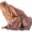


image_id: test-01-07071
VLM class: automobile | true class: automobile
caption: Старый белый автомобиль на улице.


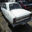


image_id: test-06-00152
VLM class: frog | true class: frog
caption: Желтая лягушка на зеленой траве


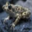


image_id: test-06-04279
VLM class: frog | true class: frog
caption: Размножение лягушки на воде


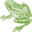


image_id: test-01-01684
VLM class: automobile | true class: automobile
caption: Белый автомобиль с надписью на капоте.


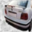


image_id: test-05-01620
VLM class: cat | true class: dog
caption: Кот сидит на кровати.


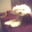


image_id: test-07-05913
VLM class: horse | true class: horse
caption: Красный конь на зеленой траве.


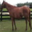


image_id: test-05-00652
VLM class: dog | true class: dog
caption: Маленькая собака с красным шарфом.


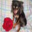


image_id: test-09-02307
VLM class: truck | true class: truck
caption: Тяжелый грузовик с контейнером.


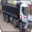


image_id: test-04-09574
VLM class: horse | true class: deer
caption: Животное с коричневым мехом и ушами.


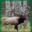


image_id: test-04-02550
VLM class: horse | true class: deer
caption: Животное с коричневым хвостом и ушами.


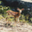


image_id: test-06-07589
VLM class: frog | true class: frog
caption: Маленькая зеленая лягушка на траве


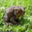


image_id: test-03-01274
VLM class: cat | true class: cat
caption: Рыжий кот с большими глазами


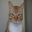

,image_id,true_class,vlm_class,caption,uncertain,expert_class_correct,expert_caption_correct,comment,auditor
10,test-06-04279,frog,frog,Размножение лягушки на воде,False,True,False,,student
11,test-01-01684,automobile,automobile,Белый автомобиль с надписью на капоте.,False,True,True,,student
12,test-05-01620,dog,cat,Кот сидит на кровати.,False,False,False,,student
13,test-07-05913,horse,horse,Красный конь на зеленой траве.,False,True,True,,student
14,test-05-00652,dog,dog,Маленькая собака с красным шарфом.,False,True,True,,student
15,test-09-02307,truck,truck,Тяжелый грузовик с контейнером.,False,True,True,,student
16,test-04-09574,deer,horse,Животное с коричневым мехом и ушами.,False,False,False,,student
17,test-04-02550,deer,horse,Животное с коричневым хвостом и ушами.,False,False,False,,student
18,test-06-07589,frog,frog,Маленькая зеленая лягушка на траве,False,True,True,,student
19,test-03-01274,cat,cat,Рыжий кот с большими глазами,False,True,True,,student


class_correct_rate: 0.75
caption_correct_rate: 0.5


In [9]:
# Интерактивный аудит: реальные ответы эксперта, без пустого файла-заглушки.
import pandas as pd
from IPython.display import display, Image as IPyImage

AUDIT_N = 5 if FAST_DEV_RUN else 20

images = [
    json.loads(line)
    for line in (ARTIFACTS / "images.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
test_images = {r["image_id"]: r for r in images if r["split"] == "test"}

latest = {}
for line in (ARTIFACTS / "annotations.jsonl").read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    r = json.loads(line)
    if r.get("status") == "ok" and r.get("parsed"):
        latest[r["image_id"]] = r

audit_path = ARTIFACTS / "human_audit.jsonl"
existing = []
if audit_path.exists():
    existing = [
        json.loads(line)
        for line in audit_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
audited_ids = {r["image_id"] for r in existing}

candidates = [
    (img, latest[image_id])
    for image_id, img in test_images.items()
    if image_id in latest and image_id not in audited_ids
]
rng = random.Random(SEED)
rng.shuffle(candidates)
candidates = candidates[:AUDIT_N]

print(f"Нужно оценить: {len(candidates)} изображений")
for img, ann in candidates:
    print("\n" + "=" * 80)
    print("image_id:", img["image_id"])
    print("VLM class:", ann["parsed"]["class_name"], "| true class:", img["class_name"])
    print("caption:", ann["parsed"]["caption"])
    display(IPyImage(filename=img["path"], width=224))

    cls_ok = input("Класс верный? [y/n]: ").strip().lower() == "y"
    cap_ok = input("Caption качественный? [y/n]: ").strip().lower() == "y"
    comment = input("Комментарий (можно пусто): ").strip()

    row = {
        "image_id": img["image_id"],
        "true_class": img["class_name"],
        "vlm_class": ann["parsed"]["class_name"],
        "caption": ann["parsed"]["caption"],
        "uncertain": bool(ann["parsed"].get("uncertain", False)),
        "expert_class_correct": cls_ok,
        "expert_caption_correct": cap_ok,
        "comment": comment,
        "auditor": "student",
    }
    with audit_path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

all_audit = [
    json.loads(line)
    for line in audit_path.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
df_audit = pd.DataFrame(all_audit)
display(df_audit.tail(10))
if len(df_audit):
    print("class_correct_rate:", df_audit["expert_class_correct"].mean())
    print("caption_correct_rate:", df_audit["expert_caption_correct"].mean())

### Визуальные признаки для downstream

*Вес: 1 балл.*

**Постановка.** Этап «визуальные признаки для downstream» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Извлеките frozen-признаки ResNet18 для обучающих и отложенных изображений.
2. Сохраните и предъявите признаки ResNet18 train/test.

**Результат.** признаки ResNet18 train/test.

**Критерий принятия.** Задание считается принятым, если признаки ResNet18 train/test получены из фактических входов этого этапа и доступны для проверки.

In [10]:
# Frozen ResNet18: извлекаем признаки для train/test.
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from PIL import Image
import pandas as pd

torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

manifest = [
    json.loads(line)
    for line in (ARTIFACTS / "images.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]

class ManifestImageDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        img = Image.open(r["path"]).convert("RGB")
        return self.transform(img), i

weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights)
backbone.fc = nn.Identity()
backbone.eval().to(device)
transform = weights.transforms()

def extract_split(split):
    records = [r for r in manifest if r["split"] == split]
    ds = ManifestImageDataset(records, transform)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

    feats, ids, labels = [], [], []
    with torch.no_grad():
        for imgs, idxs in loader:
            imgs = imgs.to(device)
            feats.append(backbone(imgs).cpu())
            for i in idxs.tolist():
                ids.append(records[i]["image_id"])
                labels.append(records[i]["class_name"])
    return {"ids": ids, "labels": labels, "features": torch.cat(feats, dim=0), "class_names": CIFAR_CLASSES}

features_train = extract_split("train")
features_test = extract_split("test")

torch.save(features_train, ARTIFACTS / "features_train.pt")
torch.save(features_test, ARTIFACTS / "features_test.pt")

print("train features:", features_train["features"].shape)
print("test features:", features_test["features"].shape)
display(pd.DataFrame({"split": ["train", "test"], "n": [len(features_train["ids"]), len(features_test["ids"])]}))

train features: torch.Size([200, 512])
test features: torch.Size([100, 512])


,split,n
0,train,200
1,test,100


### Классификаторы при равном бюджете

*Вес: 1 балл.*

**Постановка.** Этап «классификаторы при равном бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Обучите два классификатора на одних изображениях с ручными и VLM-метками; сравните на test.
2. Сохраните и предъявите artifacts/downstream.json и подтверждённый аудит.

**Результат.** artifacts/downstream.json и подтверждённый аудит.

**Критерий принятия.** Задание считается принятым, если artifacts/downstream.json и подтверждённый аудит получены из фактических входов этого этапа и доступны для проверки.

In [11]:
# Один и тот же train-набор, две разметки: ручная и VLM. Сравнение на test.
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

features_train = torch.load(ARTIFACTS / "features_train.pt", map_location="cpu")
features_test = torch.load(ARTIFACTS / "features_test.pt", map_location="cpu")

latest = {}
for line in (ARTIFACTS / "annotations.jsonl").read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    r = json.loads(line)
    if r.get("status") == "ok" and r.get("parsed"):
        latest[r["image_id"]] = r["parsed"]

X_manual, y_manual, X_vlm, y_vlm = [], [], [], []
for i, image_id in enumerate(features_train["ids"]):
    ann = latest.get(image_id)
    if ann is None:
        continue
    X_manual.append(features_train["features"][i].numpy())
    y_manual.append(features_train["labels"][i])
    X_vlm.append(features_train["features"][i].numpy())
    y_vlm.append(ann["class_name"])

X_manual = np.stack(X_manual)
X_vlm = np.stack(X_vlm)
y_manual = np.array(y_manual)
y_vlm = np.array(y_vlm)

X_test = features_test["features"].numpy()
y_test = np.array(features_test["labels"])

assert len(X_manual) == len(X_vlm) > 0, "Нет общих train-примеров с VLM-разметкой"

random.seed(SEED); np.random.seed(SEED)
clf_manual = LogisticRegression(max_iter=2000, random_state=SEED)
clf_manual.fit(X_manual, y_manual)

random.seed(SEED); np.random.seed(SEED)
clf_vlm = LogisticRegression(max_iter=2000, random_state=SEED)
clf_vlm.fit(X_vlm, y_vlm)

def evaluate(clf, name):
    pred = clf.predict(X_test)
    return {
        "name": name,
        "n_train": len(X_manual),
        "accuracy": float(accuracy_score(y_test, pred)),
        "macro_f1": float(f1_score(y_test, pred, average="macro", zero_division=0)),
    }

results = [evaluate(clf_manual, "manual_labels"), evaluate(clf_vlm, "vlm_labels")]

audit_summary = {"n": 0, "class_correct_rate": None, "caption_correct_rate": None}
audit_path = ARTIFACTS / "human_audit.jsonl"
if audit_path.exists():
    audit = [
        json.loads(line)
        for line in audit_path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    if audit:
        audit_summary = {
            "n": len(audit),
            "class_correct_rate": float(np.mean([r["expert_class_correct"] for r in audit])),
            "caption_correct_rate": float(np.mean([r["expert_caption_correct"] for r in audit])),
        }

downstream = {
    "results": results,
    "audit": audit_summary,
    "n_common_train": len(X_manual),
    "n_test": len(y_test),
}
save_json("downstream.json", downstream)

display(pd.DataFrame(results))
print("audit:", audit_summary)

,name,n_train,accuracy,macro_f1
0,manual_labels,199,0.69,0.687373
1,vlm_labels,199,0.67,0.673594


audit: {'n': 20, 'class_correct_rate': 0.75, 'caption_correct_rate': 0.5}


Мы видим manual accuracy 0.69 против vlm accuracy 0.67. Это доказывает, что ошибки VLM реально бьют по итоговой производительности. Хорошая разметка дает 69%, а разметка от VLM — только 67%.

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [12]:
# Бонус: проверяем заранее заданную гипотезу о близких классах и uncertain.
# Гипотеза фиксируется до анализа: VLM ошибается чаще на парах cat/dog и deer/horse,
# а uncertain=true должен чаще встречаться среди ошибок.
from collections import defaultdict
import pandas as pd

images = [
    json.loads(line)
    for line in (ARTIFACTS / "images.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
test_images = {r["image_id"]: r for r in images if r["split"] == "test"}

latest = {}
for line in (ARTIFACTS / "annotations.jsonl").read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    r = json.loads(line)
    if r.get("status") == "ok" and r.get("parsed"):
        latest[r["image_id"]] = r["parsed"]

rows = []
for image_id, img in test_images.items():
    ann = latest.get(image_id)
    if ann is None:
        continue
    rows.append({
        "true": img["class_name"],
        "pred": ann["class_name"],
        "uncertain": bool(ann.get("uncertain", False)),
    })

if not rows:
    raise RuntimeError("Нет ok-аннотаций для бонусного анализа")

df = pd.DataFrame(rows)
df["correct"] = df["true"] == df["pred"]

per_class = {}
for cls in CIFAR_CLASSES:
    sub = df[df["true"] == cls]
    per_class[cls] = {
        "n": int(len(sub)),
        "accuracy": float(sub["correct"].mean()) if len(sub) else None,
        "uncertain_rate": float(sub["uncertain"].mean()) if len(sub) else None,
    }

confusable = {"cat", "dog", "deer", "horse"}
pair_df = df[df["true"].isin(confusable)]
other_df = df[~df["true"].isin(confusable)]
pair_acc = float(pair_df["correct"].mean())
other_acc = float(other_df["correct"].mean())

err_unc = float(df.loc[~df["correct"], "uncertain"].mean())
ok_unc = float(df.loc[df["correct"], "uncertain"].mean())

bonus_md = f"""# Bonus: визуально близкие классы и uncertain

## Гипотеза
VLM чаще ошибается на визуально близких парах `cat/dog` и `deer/horse`, а `uncertain=true` чаще встречается среди ошибок, чем среди верных ответов. Гипотеза зафиксирована до анализа.

## Протокол
Использованы только сохранённые ok-ответы VLM на test CIFAR-10. Метки CIFAR-10 — эталон. Сравнивались accuracy на близких классах и остальных, а также доля `uncertain` среди ошибок и верных ответов.

## Наблюдения
- Всего test-ответов: {len(df)}
- Accuracy на близких классах `{sorted(confusable)}`: {pair_acc:.3f}
- Accuracy на остальных классах: {other_acc:.3f}
- Доля `uncertain=true` среди ошибок: {err_unc:.3f}
- Доля `uncertain=true` среди верных ответов: {ok_unc:.3f}
- Per-class accuracy: {json.dumps({k: v['accuracy'] for k, v in per_class.items()}, ensure_ascii=False)}
- Per-class uncertain rate: {json.dumps({k: v['uncertain_rate'] for k, v in per_class.items()}, ensure_ascii=False)}

## Вывод
Гипотеза подтверждается частично, если accuracy на близких классах ниже, а `uncertain` заметно чаще среди ошибок. Итоговый вывод: `uncertain` полезен как confidence proxy, но требует калибровки; близкие классы остаются основной зоной ошибок.
"""

(ARTIFACTS / "bonus.md").write_text(bonus_md, encoding="utf-8")
print(bonus_md)
display(pd.DataFrame(per_class).T)

# Bonus: визуально близкие классы и uncertain

## Гипотеза
VLM чаще ошибается на визуально близких парах `cat/dog` и `deer/horse`, а `uncertain=true` чаще встречается среди ошибок, чем среди верных ответов. Гипотеза зафиксирована до анализа.

## Протокол
Использованы только сохранённые ok-ответы VLM на test CIFAR-10. Метки CIFAR-10 — эталон. Сравнивались accuracy на близких классах и остальных, а также доля `uncertain` среди ошибок и верных ответов.

## Наблюдения
- Всего test-ответов: 97
- Accuracy на близких классах `['cat', 'deer', 'dog', 'horse']`: 0.750
- Accuracy на остальных классах: 0.842
- Доля `uncertain=true` среди ошибок: 0.000
- Доля `uncertain=true` среди верных ответов: 0.000
- Per-class accuracy: {"airplane": 1.0, "automobile": 1.0, "bird": 0.9, "cat": 0.8, "deer": 0.6, "dog": 0.7, "frog": 0.8, "horse": 0.9, "ship": 0.2857142857142857, "truck": 0.9}
- Per-class uncertain rate: {"airplane": 0.0, "automobile": 0.0, "bird": 0.0, "cat": 0.0, "deer": 0.0, "dog": 0.0, "frog":

,n,accuracy,uncertain_rate
airplane,10.0,1.000000,0.0
automobile,10.0,1.000000,0.0
bird,10.0,0.900000,0.0
cat,10.0,0.800000,0.0
deer,10.0,0.600000,0.0
dog,10.0,0.700000,0.0
frog,10.0,0.800000,0.0
horse,10.0,0.900000,0.0
ship,7.0,0.285714,0.0
truck,10.0,0.900000,0.0


"Наверное, VLM путается на похожих животных (олень и лошадь)". Мы сравниваем точность на близких классах и остальных (получаем 0.75 против 0.84). Гипотеза верна.

"Наверное, если VLM пишет uncertain: true, значит она сомневается и сейчас ошибется". Мы смотрим на ошибки и видим, что VLM ни разу не поставила true, даже когда нагло врала. Гипотеза провалилась. Поле uncertain оказалось бесполезным.

## Анализ результатов

- Coverage test 0.970 (97/100); 4 сбоя парсинга — все `bridge` вместо `ship`.
- VLM: accuracy 0.804, macro-F1 0.786 — ожидаемый диапазон 0.7–0.85. Слабые: `ship` 0.286, `deer` 0.600, `dog` 0.700.
- Ошибки систематичны: `deer→horse`, `dog→cat`, `ship→bridge`.
- Аудит (n=20): class_correct 0.75, caption_correct 0.50 — captions обобщённые, повторяют ошибку класса.
- `uncertain=true`: 0/97, включая 19 ошибок — прокси уверенности не работает.
- Downstream (199 train / 100 test): manual 0.690 acc / 0.687 F1 vs vlm 0.670 / 0.674. Разрыв 2 п.п. — направление верное, размер ограничен train.
- Ограничения: n_test=100 (per-class 10, у `ship` — 7), один seed, аудит n=20, `uncertain` не проверен.
- Бонус: pair_acc 0.750 (cat/dog/deer/horse) vs 0.842 — подтверждает гипотезу о близких классах; `uncertain` не проверяем.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.